In [7]:

# ============================================================
#  PREPARAÇÃO DOS DADOS - MCA PENSE 2024
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

from sklearn.metrics import silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Arquivo de entrada
arquivo = (
    "/Users/claudiojacomassi/Documents/GitHub/"
    "Suicidio_adolescentes_Brasil/"
    "02_Tratamento_dados_database_PENSE_2024/"
    "02_Scripts_tratamento_dados_PENSE_2024/"
    "08_PENSE2024_MCA_COORDENADAS.feather"
)

# Carregar dados
df_mca = pd.read_feather(arquivo)

print("=" * 65)
print("BASE DE COORDENADAS MCA - PENSE 2024")
print("=" * 65)

print(f"\nDimensões da base: {df_mca.shape}")
print(f"Quantidade de registros: {len(df_mca):,}")
print(f"Quantidade de colunas: {len(df_mca.columns)}")

# Identificar automaticamente colunas de coordenadas MCA
padrao_mca = re.compile(
    r"(dim|dimension|coord|axis|eixo|factor|component)",
    re.IGNORECASE
)

colunas_numericas = df_mca.select_dtypes(
    include=[np.number]
).columns.tolist()

colunas_mca = [
    c for c in colunas_numericas
    if padrao_mca.search(str(c))
]

# Caso os nomes não identifiquem as dimensões,
# utilizar todas as colunas numéricas, exceto identificadores.
if len(colunas_mca) < 2:

    colunas_mca = [
        c for c in colunas_numericas
        if not re.search(
            r"(^id$|^id_|_id$|codigo|código|identificador)",
            str(c),
            re.IGNORECASE
        )
    ]

print("\nColunas utilizadas na análise MCA:")
print(colunas_mca)

if len(colunas_mca) < 2:
    raise ValueError(
        "Não foram encontradas pelo menos duas colunas numéricas "
        "para realizar a clusterização."
    )

# Criar matriz de coordenadas
X = df_mca[colunas_mca].copy()

# Substituir valores infinitos por NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Remover registros com coordenadas ausentes
mascara_validos = X.notna().all(axis=1)

X = X.loc[mascara_validos].copy()

# Preservar índice dos registros originais
indices_validos = X.index

print("\nResultado da preparação:")
print(f"Registros válidos: {len(X):,}")
print(f"Registros removidos: {len(df_mca) - len(X):,}")
print(f"Dimensões MCA utilizadas: {X.shape[1]}")

# Converter para matriz NumPy
X_array = X.to_numpy(dtype=float)

# Identificar as duas primeiras dimensões para gráficos
dim1 = colunas_mca[0]
dim2 = colunas_mca[1]

print(f"\nGráficos utilizarão: {dim1} x {dim2}")


BASE DE COORDENADAS MCA - PENSE 2024

Dimensões da base: (118036, 21)
Quantidade de registros: 118,036
Quantidade de colunas: 21

Colunas utilizadas na análise MCA:
['indice_original', 'MCA_1', 'MCA_2', 'MCA_3', 'MCA_4', 'MCA_5', 'MCA_6', 'MCA_7', 'MCA_8', 'MCA_9', 'MCA_10', 'MCA_11', 'MCA_12', 'MCA_13', 'MCA_14', 'MCA_15', 'MCA_16', 'MCA_17', 'MCA_18', 'MCA_19', 'MCA_20']

Resultado da preparação:
Registros válidos: 118,036
Registros removidos: 0
Dimensões MCA utilizadas: 21

Gráficos utilizarão: indice_original x MCA_1


Executando GMM...

K=2 | BIC=214037.16 | AIC=213214.46
K=3 | BIC=-63157.53 | AIC=-64396.41
K=4 | BIC=-331411.42 | AIC=-333066.49
K=5 | BIC=-579965.02 | AIC=-582036.27
K=6 | BIC=-706343.51 | AIC=-708830.95
K=7 | BIC=-737863.43 | AIC=-740767.05
K=8 | BIC=-817973.81 | AIC=-821293.62
K=9 | BIC=-869669.31 | AIC=-873405.31
K=10 | BIC=-904187.57 | AIC=-908339.75
K=11 | BIC=-972703.87 | AIC=-977272.24
K=12 | BIC=-1023351.85 | AIC=-1028336.40
K=13 | BIC=-1036211.63 | AIC=-1041612.37
K=14 | BIC=-1064760.98 | AIC=-1070577.91
K=15 | BIC=-1095403.76 | AIC=-1101636.87
K=16 | BIC=-1144994.89 | AIC=-1151644.19
K=17 | BIC=-1194557.90 | AIC=-1201623.38
K=18 | BIC=-1221641.11 | AIC=-1229122.78
K=19 | BIC=-1239975.38 | AIC=-1247873.24
K=20 | BIC=-1205353.27 | AIC=-1213667.31

RESULTADOS GMM

Melhor número de clusters pelo BIC: 19
Silhouette Score: -0.2111

Distribuição dos clusters:
Cluster_GMM
0      7976
1       613
2     10079
3      8047
4      8688
5      1553
6      4454
7      9058
8      6893
9   

ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/.venv/lib/python3.12/site-packages/pandas/io/formats/format.py)

    Clusters         BIC         AIC  Convergiu  Iteracoes
0          2   214037.16   213214.46       True          7
1          3   -63157.53   -64396.41       True         23
2          4  -331411.42  -333066.49       True         29
3          5  -579965.02  -582036.27       True         37
4          6  -706343.51  -708830.95       True         75
5          7  -737863.43  -740767.05       True         45
6          8  -817973.81  -821293.62       True         59
7          9  -869669.31  -873405.31       True         46
8         10  -904187.57  -908339.75       True         50
9         11  -972703.87  -977272.24       True         49
10        12 -1023351.85 -1028336.40       True         58
11        13 -1036211.63 -1041612.37       True         33
12        14 -1064760.98 -1070577.91       True         40
13        15 -1095403.76 -1101636.87       True         53
14        16 -1144994.89 -1151644.19       True         53
15        17 -1194557.90 -1201623.38       True         

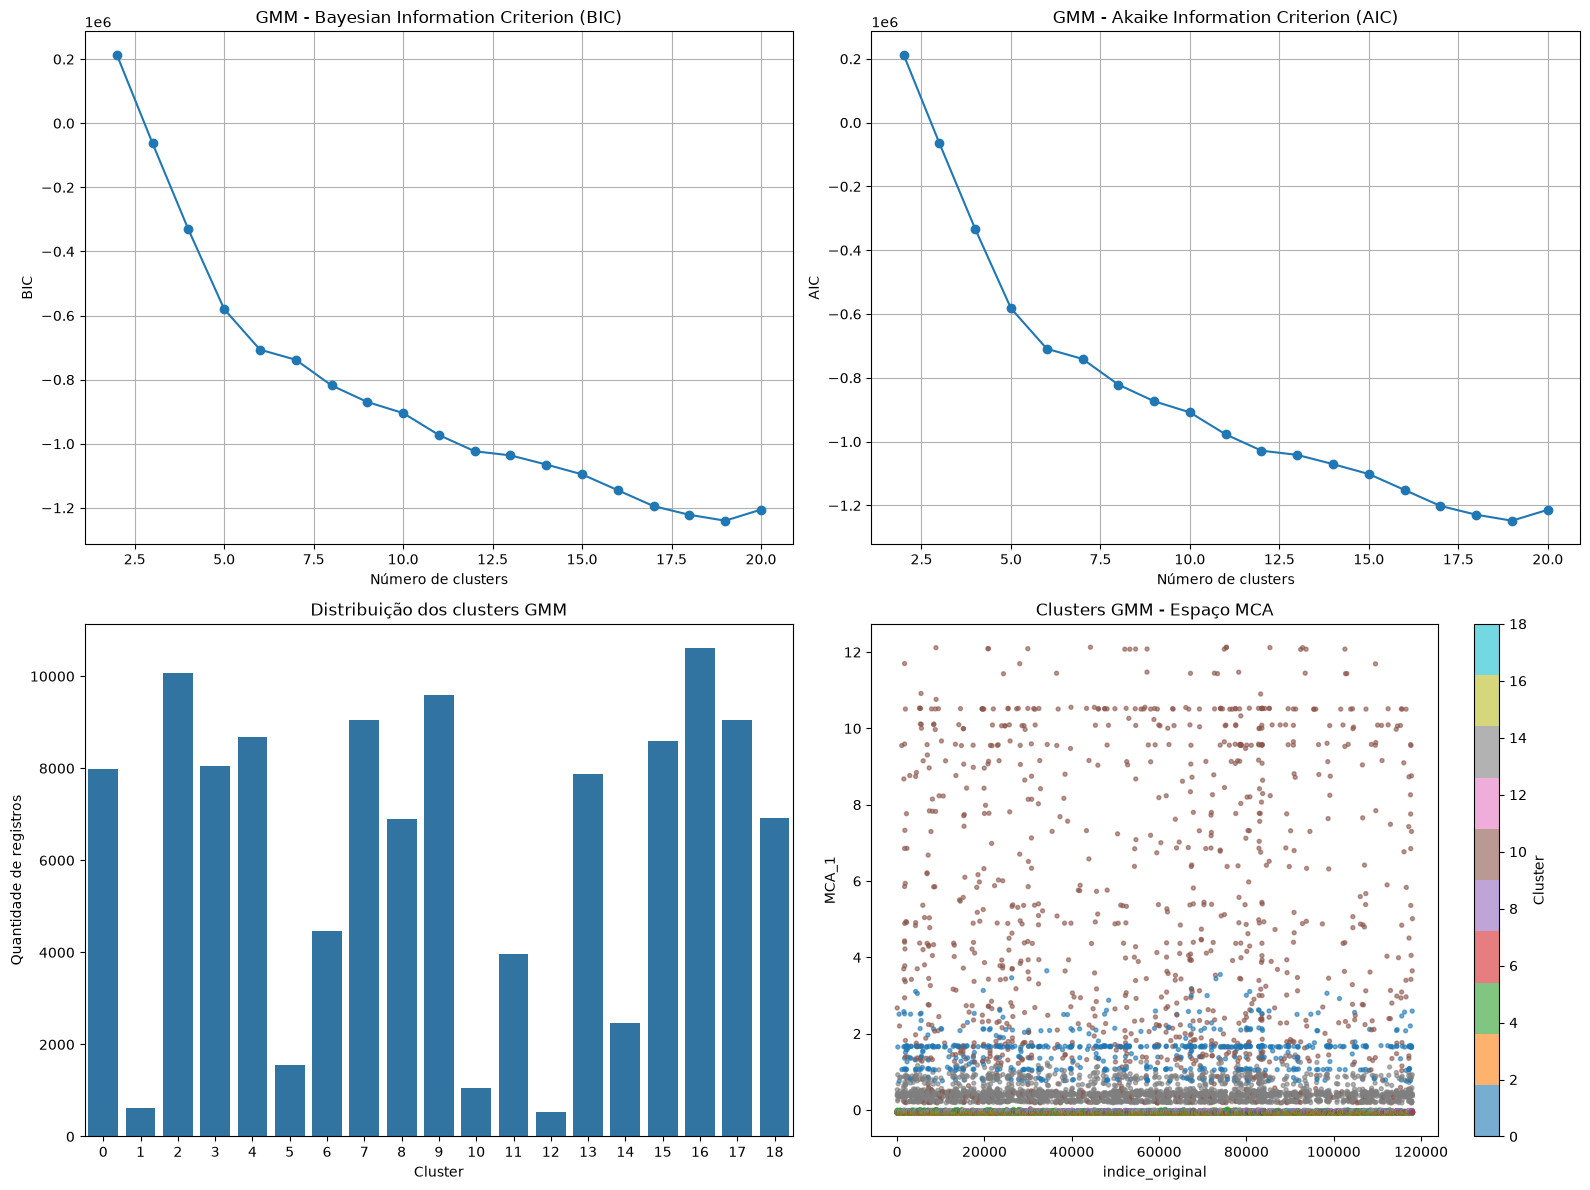


Probabilidade média de pertencimento:
Cluster 0: 0.0674
Cluster 1: 0.0052
Cluster 2: 0.0848
Cluster 3: 0.0677
Cluster 4: 0.0729
Cluster 5: 0.0138
Cluster 6: 0.0377
Cluster 7: 0.0762
Cluster 8: 0.0583
Cluster 9: 0.0817
Cluster 10: 0.0090
Cluster 11: 0.0340
Cluster 12: 0.0045
Cluster 13: 0.0670
Cluster 14: 0.0210
Cluster 15: 0.0735
Cluster 16: 0.0901
Cluster 17: 0.0764
Cluster 18: 0.0589

Registros com classificação de baixa confiança (< 0.60):
5444


In [8]:

# ============================================================
#  GMM - GAUSSIAN MIXTURE MODELS
#  PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.mixture import GaussianMixture

# Parâmetros
K_MIN = 2
K_MAX = 20

# Avaliação de diferentes quantidades de clusters
resultados_gmm = []

modelos_gmm = {}

print("Executando GMM...\n")

for k in range(K_MIN, K_MAX + 1):

    modelo = GaussianMixture(
        n_components=k,
        covariance_type="diag",
        random_state=42,
        n_init=3,
        max_iter=300,
        reg_covar=1e-6
    )

    modelo.fit(X_array)

    bic = modelo.bic(X_array)
    aic = modelo.aic(X_array)

    modelos_gmm[k] = modelo

    resultados_gmm.append({
        "Clusters": k,
        "BIC": bic,
        "AIC": aic,
        "Convergiu": modelo.converged_,
        "Iteracoes": modelo.n_iter_
    })

    print(f"K={k} | BIC={bic:.2f} | AIC={aic:.2f}")

# Tabela comparativa
df_gmm = pd.DataFrame(resultados_gmm)

# Selecionar modelo pelo menor BIC
melhor_k_gmm = int(
    df_gmm.loc[df_gmm["BIC"].idxmin(), "Clusters"]
)

modelo_gmm = modelos_gmm[melhor_k_gmm]

# Classificação final
clusters_gmm = modelo_gmm.predict(X_array)

# Probabilidades de pertencimento
probabilidades_gmm = modelo_gmm.predict_proba(X_array)

# Confiança da classificação: maior probabilidade
confianca_gmm = probabilidades_gmm.max(axis=1)

# Criar resultados
df_resultado_gmm = df_mca.loc[indices_validos].copy()

df_resultado_gmm["Cluster_GMM"] = clusters_gmm
df_resultado_gmm["Confianca_GMM"] = confianca_gmm

# Silhouette Score (amostra para reduzir custo computacional)
if len(X) > 10000:
    rng = np.random.RandomState(42)
    amostra = rng.choice(len(X), 10000, replace=False)
else:
    amostra = np.arange(len(X))

labels_amostra = clusters_gmm[amostra]

if len(np.unique(labels_amostra)) > 1:
    silhouette_gmm = silhouette_score(
        X_array[amostra],
        labels_amostra
    )
else:
    silhouette_gmm = np.nan

# ============================================================
# RESULTADOS
# ============================================================

print("\n" + "=" * 65)
print("RESULTADOS GMM")
print("=" * 65)

print(f"\nMelhor número de clusters pelo BIC: {melhor_k_gmm}")
print(f"Silhouette Score: {silhouette_gmm:.4f}")

print("\nDistribuição dos clusters:")

print(
    df_resultado_gmm["Cluster_GMM"]
    .value_counts()
    .sort_index()
)

print("\nConfiança média de classificação por cluster:")

print(
    df_resultado_gmm.groupby("Cluster_GMM")["Confianca_GMM"]
    .mean()
    .round(4)
)

print("\nComparação BIC e AIC:")

display(df_gmm.round(2))

# ============================================================
# GRÁFICOS
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1 - BIC
axes[0, 0].plot(
    df_gmm["Clusters"],
    df_gmm["BIC"],
    marker="o"
)

axes[0, 0].set_title("GMM - Bayesian Information Criterion (BIC)")
axes[0, 0].set_xlabel("Número de clusters")
axes[0, 0].set_ylabel("BIC")
axes[0, 0].grid(True)

# 2 - AIC
axes[0, 1].plot(
    df_gmm["Clusters"],
    df_gmm["AIC"],
    marker="o"
)

axes[0, 1].set_title("GMM - Akaike Information Criterion (AIC)")
axes[0, 1].set_xlabel("Número de clusters")
axes[0, 1].set_ylabel("AIC")
axes[0, 1].grid(True)

# 3 - Distribuição dos clusters
sns.countplot(
    x="Cluster_GMM",
    data=df_resultado_gmm,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Distribuição dos clusters GMM")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("Quantidade de registros")

# 4 - Visualização MCA
scatter = axes[1, 1].scatter(
    X[dim1],
    X[dim2],
    c=clusters_gmm,
    cmap="tab10",
    s=8,
    alpha=0.6
)

axes[1, 1].set_title("Clusters GMM - Espaço MCA")
axes[1, 1].set_xlabel(dim1)
axes[1, 1].set_ylabel(dim2)

plt.colorbar(scatter, ax=axes[1, 1], label="Cluster")

plt.tight_layout()
plt.show()

# ============================================================
# ANÁLISE ADICIONAL
# ============================================================

print("\nProbabilidade média de pertencimento:")

for k in range(melhor_k_gmm):
    print(
        f"Cluster {k}: "
        f"{probabilidades_gmm[:, k].mean():.4f}"
    )

print("\nRegistros com classificação de baixa confiança (< 0.60):")

print(
    (confianca_gmm < 0.60).sum()
)


In [9]:
# ============================================================
# VERIFICAÇÃO DAS VARIÁVEIS NECESSÁRIAS
# ============================================================

variaveis_necessarias = [
    "X_array",
    "clusters_gmm",
    "probabilidades_gmm",
    "confianca_gmm",
    "modelo_gmm",
    "melhor_k_gmm",
    "df_mca"
]

variaveis_ausentes = [
    v for v in variaveis_necessarias
    if v not in globals()
]

if variaveis_ausentes:

    raise NameError(
        f"Variáveis não encontradas: {variaveis_ausentes}. "
        "Execute primeiro as células 0 e 1 do notebook."
    )

print("Todas as variáveis necessárias estão disponíveis.")

Todas as variáveis necessárias estão disponíveis.



AVALIAÇÃO AMPLIADA DO GMM - PENSE 2024

MÉTRICAS GERAIS


ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/.venv/lib/python3.12/site-packages/pandas/io/formats/format.py)

                       Metrica     Resultado
0                          BIC -1.239975e+06
1                          AIC -1.247873e+06
2         Log-Likelihood médio  5.292900e+00
3         Log-Likelihood total  6.247526e+05
4             Silhouette Score -2.111000e-01
5            Calinski-Harabasz  1.504260e+01
6               Davies-Bouldin  4.190103e+02
7               Entropia média  1.624000e-01
8         Entropia normalizada  5.520000e-02
9   Classification Uncertainty  6.580000e-02
10  Cluster Balance (entropia)  9.356000e-01


SILHOUETTE POR CLUSTER


ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/.venv/lib/python3.12/site-packages/pandas/io/formats/format.py)

          Media  Mediana  Desvio_Padrao  Minimo  Maximo  Observacoes
Cluster                                                             
0       -0.1915  -0.1263         0.1614 -0.5157 -0.0237          680
1       -0.1875  -0.1807         0.1515 -0.4186  0.0161           40
2       -0.2037  -0.1530         0.1361 -0.4984 -0.0515          838
3       -0.2245  -0.2094         0.1222 -0.4442 -0.0575          657
4       -0.2080  -0.1551         0.1355 -0.4897 -0.0567          787
5        0.0695   0.2375         0.3143 -0.4838  0.3370          130
6       -0.1428  -0.0735         0.1987 -0.5417  0.0672          365
7       -0.2229  -0.1689         0.1352 -0.4946 -0.0706          740
8       -0.1867  -0.1700         0.1373 -0.4315 -0.0006          634
9       -0.2214  -0.2586         0.1173 -0.3860 -0.0463          804
10      -0.2148  -0.1973         0.1259 -0.4376 -0.0500           93
11      -0.1836  -0.2197         0.1408 -0.3569  0.0616          322
12      -0.1765  -0.1531         0

... (8 outputs left out)

    Cluster  Percentual_Classificacao  Massa_Probabilistica_Percentual
0         0                      6.76                             6.74
1         1                      0.52                             0.52
2         2                      8.54                             8.48
3         3                      6.82                             6.77
4         4                      7.36                             7.29
5         5                      1.32                             1.38
6         6                      3.77                             3.77
7         7                      7.67                             7.62
8         8                      5.84                             5.83
9         9                      8.12                             8.17
10       10                      0.89                             0.90
11       11                      3.37                             3.40
12       12                      0.45                             0.45
13    


DISTÂNCIA ENTRE AS MÉDIAS DOS COMPONENTES


ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/.venv/lib/python3.12/site-packages/pandas/io/formats/format.py)

             Cluster 0   Cluster 1   Cluster 2   Cluster 3   Cluster 4  \
Cluster 0       0.0000  10807.3031   2806.5849   7950.1260   3725.7557   
Cluster 1   10807.3031      0.0000   8000.7185   2857.1785   7081.5478   
Cluster 2    2806.5849   8000.7185      0.0000   5143.5412    919.1708   
Cluster 3    7950.1260   2857.1785   5143.5412      0.0000   4224.3704   
Cluster 4    3725.7557   7081.5478    919.1708   4224.3704      0.0000   
Cluster 5   31630.6954  20823.3930  28824.1106  23680.5695  27904.9398   
Cluster 6     818.3448  11625.6477   3624.9296   8768.4706   4544.1003   
Cluster 7    2986.5018   7820.8016    179.9175   4963.6242    739.2539   
Cluster 8    7634.0504   3173.2539   4827.4657    316.0766   3908.2949   
Cluster 9   12779.2016   1971.9016   9972.6168   4829.0757   9053.4460   
Cluster 10  10443.2849    364.0468   7636.7006   2493.1628   6717.5300   
Cluster 11  14206.5362   3399.2351  11399.9515   6256.4103  10480.7807   
Cluster 12   6735.4910  17542.7933   9

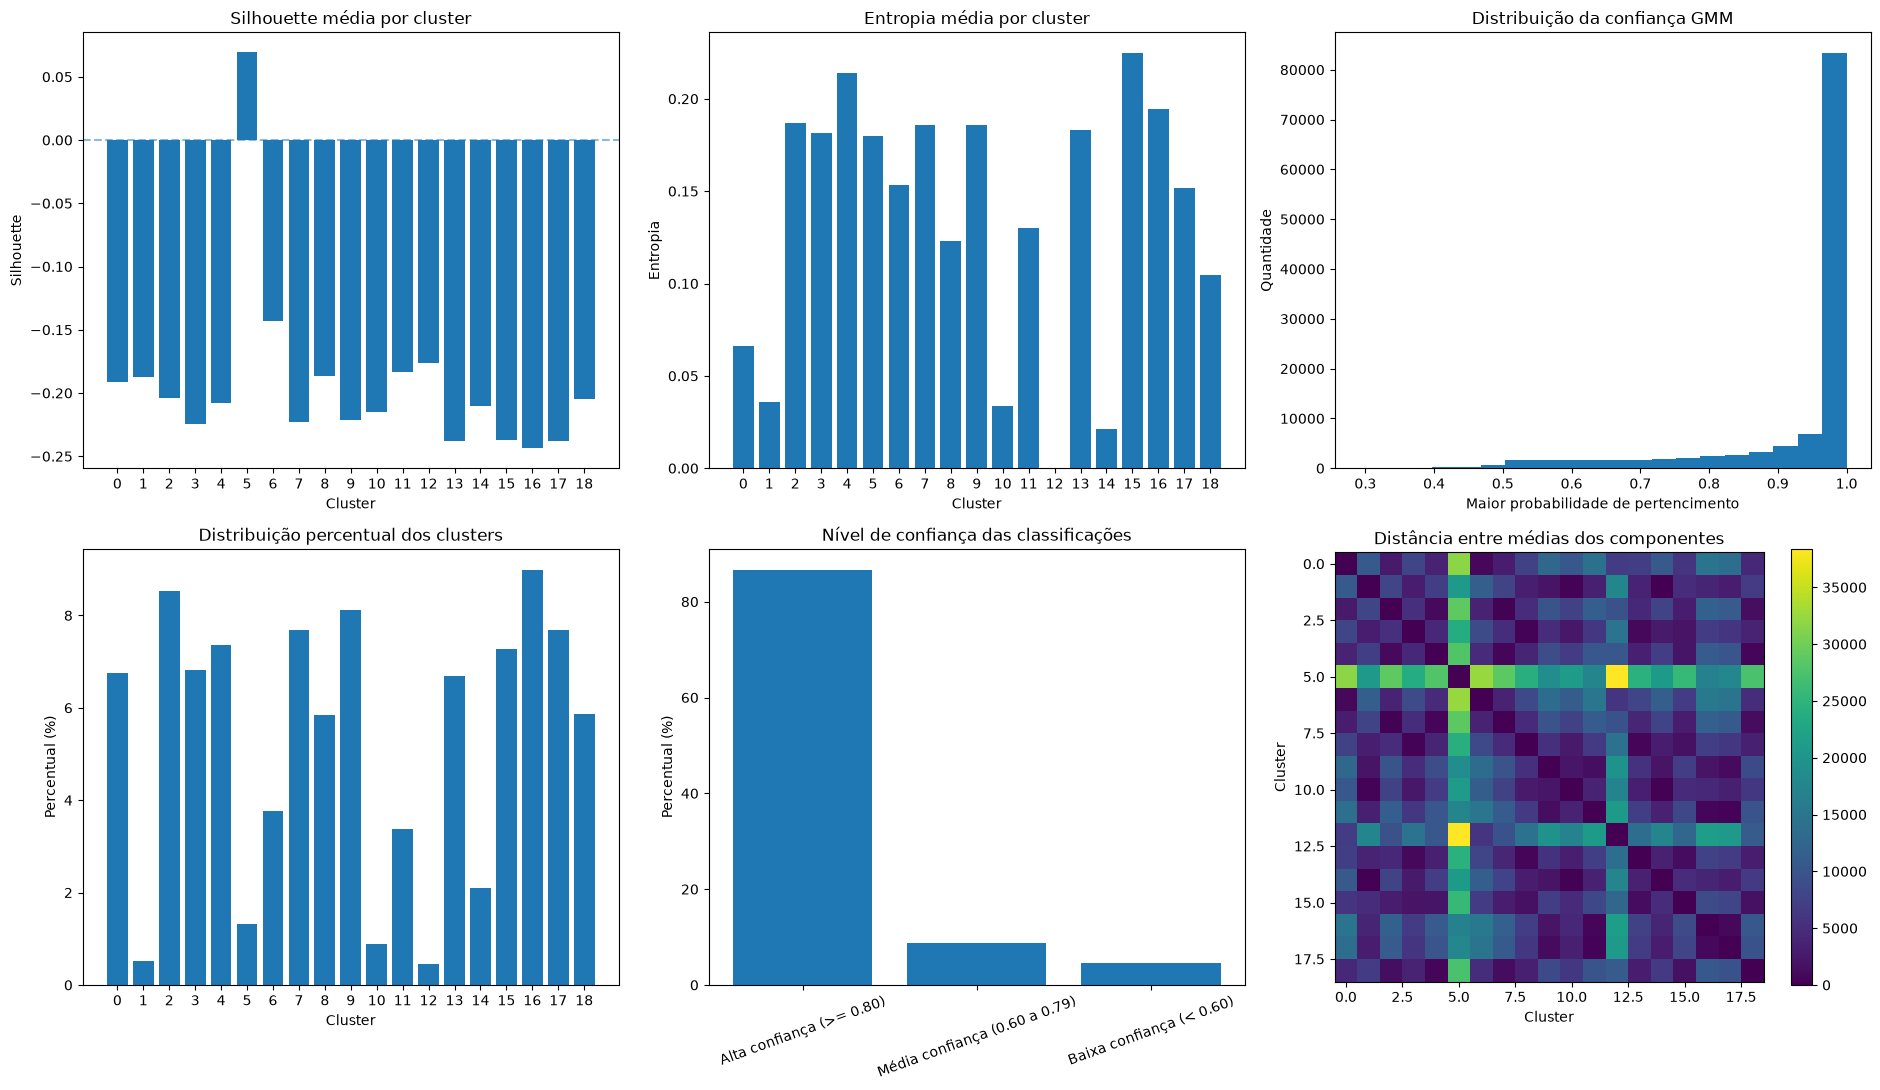


Avaliação ampliada do GMM concluída.


In [10]:

# ============================================================
# 9. MÉTRICAS ADICIONAIS DE AVALIAÇÃO DO GMM
# PENSE 2024 - COORDENADAS MCA
# ============================================================

from sklearn.metrics import (
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_samples,
    silhouette_score,
    adjusted_rand_score,
    pairwise_distances
)

from sklearn.mixture import GaussianMixture

# ------------------------------------------------------------
# 9.1. PREPARAÇÃO DA AMOSTRA
# ------------------------------------------------------------

# Amostra fixa para métricas que utilizam distâncias
MAX_AMOSTRA = 10000

if len(X_array) > MAX_AMOSTRA:

    rng = np.random.RandomState(42)

    indices_amostra_gmm = rng.choice(
        len(X_array),
        MAX_AMOSTRA,
        replace=False
    )

else:

    indices_amostra_gmm = np.arange(len(X_array))

X_avaliacao = X_array[indices_amostra_gmm]

clusters_avaliacao = clusters_gmm[indices_amostra_gmm]

probabilidades_avaliacao = probabilidades_gmm[
    indices_amostra_gmm
]

# ------------------------------------------------------------
# 9.2. CALINSKI-HARABASZ INDEX
# ------------------------------------------------------------

ch_score_gmm = calinski_harabasz_score(
    X_avaliacao,
    clusters_avaliacao
)

# ------------------------------------------------------------
# 9.3. DAVIES-BOULDIN INDEX
# ------------------------------------------------------------

db_score_gmm = davies_bouldin_score(
    X_avaliacao,
    clusters_avaliacao
)

# ------------------------------------------------------------
# 9.4. SILHOUETTE POR CLUSTER
# ------------------------------------------------------------

silhouette_individual_gmm = silhouette_samples(
    X_avaliacao,
    clusters_avaliacao
)

df_silhouette_gmm = pd.DataFrame({
    "Cluster": clusters_avaliacao,
    "Silhouette": silhouette_individual_gmm
})

silhouette_clusters_gmm = (
    df_silhouette_gmm
    .groupby("Cluster")["Silhouette"]
    .agg(["mean", "median", "std", "min", "max", "count"])
    .round(4)
)

silhouette_clusters_gmm.columns = [
    "Media",
    "Mediana",
    "Desvio_Padrao",
    "Minimo",
    "Maximo",
    "Observacoes"
]

# ------------------------------------------------------------
# 9.5. ENTROPIA DAS PROBABILIDADES
# ------------------------------------------------------------

# Entropia individual:
# Quanto maior, maior a incerteza sobre o cluster.

epsilon = 1e-12

entropia_individual = -np.sum(
    probabilidades_gmm *
    np.log(probabilidades_gmm + epsilon),
    axis=1
)

# Entropia máxima possível = log(K)
entropia_maxima = np.log(melhor_k_gmm)

# Entropia normalizada entre 0 e 1
entropia_normalizada_individual = (
    entropia_individual / entropia_maxima
)

# Média geral
entropia_media_gmm = entropia_individual.mean()

entropia_normalizada_media_gmm = (
    entropia_normalizada_individual.mean()
)

# ------------------------------------------------------------
# 9.6. CLASSIFICATION UNCERTAINTY
# ------------------------------------------------------------

# Incerteza = 1 - maior probabilidade de pertencimento

incerteza_gmm = 1 - confianca_gmm

incerteza_media_gmm = incerteza_gmm.mean()

# Classificação de alta, média e baixa confiança

alta_confianca = np.sum(confianca_gmm >= 0.80)

media_confianca = np.sum(
    (confianca_gmm >= 0.60) &
    (confianca_gmm < 0.80)
)

baixa_confianca = np.sum(confianca_gmm < 0.60)

df_confianca_gmm = pd.DataFrame({
    "Classificacao": [
        "Alta confiança (>= 0.80)",
        "Média confiança (0.60 a 0.79)",
        "Baixa confiança (< 0.60)"
    ],
    "Quantidade": [
        alta_confianca,
        media_confianca,
        baixa_confianca
    ],
    "Percentual": [
        alta_confianca / len(X_array) * 100,
        media_confianca / len(X_array) * 100,
        baixa_confianca / len(X_array) * 100
    ]
})

# ------------------------------------------------------------
# 9.7. LOG-LIKELIHOOD
# ------------------------------------------------------------

# Score médio de log-likelihood por observação
log_likelihood_medio = modelo_gmm.score(X_array)

# Log-likelihood total
log_likelihood_total = (
    modelo_gmm.score(X_array) * len(X_array)
)

# ------------------------------------------------------------
# 9.8. DISTRIBUIÇÃO E EQUILÍBRIO DOS CLUSTERS
# ------------------------------------------------------------

tamanhos_gmm = np.bincount(
    clusters_gmm,
    minlength=melhor_k_gmm
)

percentuais_gmm = (
    tamanhos_gmm / len(clusters_gmm)
) * 100

df_balance_gmm = pd.DataFrame({
    "Cluster": range(melhor_k_gmm),
    "Quantidade": tamanhos_gmm,
    "Percentual": percentuais_gmm
})

# Entropia do tamanho dos clusters
proporcoes_gmm = tamanhos_gmm / tamanhos_gmm.sum()

entropia_balance_gmm = -np.sum(
    proporcoes_gmm[proporcoes_gmm > 0] *
    np.log(proporcoes_gmm[proporcoes_gmm > 0])
)

entropia_balance_normalizada = (
    entropia_balance_gmm / np.log(melhor_k_gmm)
    if melhor_k_gmm > 1 else np.nan
)

# Proporção probabilística média de cada componente
massa_probabilistica_gmm = probabilidades_gmm.mean(axis=0)

df_massa_gmm = pd.DataFrame({
    "Cluster": range(melhor_k_gmm),
    "Percentual_Classificacao": percentuais_gmm,
    "Massa_Probabilistica_Percentual":
        massa_probabilistica_gmm * 100
})

# ------------------------------------------------------------
# 9.9. DISTÂNCIA ENTRE AS MÉDIAS DOS COMPONENTES
# ------------------------------------------------------------

distancias_medias_gmm = pairwise_distances(
    modelo_gmm.means_,
    metric="euclidean"
)

df_distancias_gmm = pd.DataFrame(
    distancias_medias_gmm,
    index=[f"Cluster {k}" for k in range(melhor_k_gmm)],
    columns=[f"Cluster {k}" for k in range(melhor_k_gmm)]
)

# ------------------------------------------------------------
# 9.10. RESULTADOS CONSOLIDADOS
# ------------------------------------------------------------

resultados_metricas_gmm = pd.DataFrame({

    "Metrica": [
        "BIC",
        "AIC",
        "Log-Likelihood médio",
        "Log-Likelihood total",
        "Silhouette Score",
        "Calinski-Harabasz",
        "Davies-Bouldin",
        "Entropia média",
        "Entropia normalizada",
        "Classification Uncertainty",
        "Cluster Balance (entropia)"
    ],

    "Resultado": [
        modelo_gmm.bic(X_array),
        modelo_gmm.aic(X_array),
        log_likelihood_medio,
        log_likelihood_total,
        silhouette_score(X_avaliacao, clusters_avaliacao),
        ch_score_gmm,
        db_score_gmm,
        entropia_media_gmm,
        entropia_normalizada_media_gmm,
        incerteza_media_gmm,
        entropia_balance_normalizada
    ]
})

print("\n" + "=" * 75)
print("AVALIAÇÃO AMPLIADA DO GMM - PENSE 2024")
print("=" * 75)

print("\nMÉTRICAS GERAIS")

display(resultados_metricas_gmm.round(4))

print("\nSILHOUETTE POR CLUSTER")

display(silhouette_clusters_gmm)

print("\nCLASSIFICAÇÃO POR NÍVEL DE CONFIANÇA")

display(df_confianca_gmm.round(2))

print("\nDISTRIBUIÇÃO DOS CLUSTERS")

display(df_balance_gmm.round(2))

print("\nMASSA PROBABILÍSTICA DOS COMPONENTES")

display(df_massa_gmm.round(2))

print("\nDISTÂNCIA ENTRE AS MÉDIAS DOS COMPONENTES")

display(df_distancias_gmm.round(4))

# ------------------------------------------------------------
# 9.11. GRÁFICOS DAS MÉTRICAS
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

# Gráfico 1 - Silhouette por cluster

axes[0, 0].bar(
    silhouette_clusters_gmm.index.astype(str),
    silhouette_clusters_gmm["Media"]
)

axes[0, 0].axhline(
    0,
    linestyle="--",
    alpha=0.5
)

axes[0, 0].set_title("Silhouette média por cluster")
axes[0, 0].set_xlabel("Cluster")
axes[0, 0].set_ylabel("Silhouette")

# Gráfico 2 - Entropia por cluster

entropia_por_cluster = pd.DataFrame({
    "Cluster": clusters_gmm,
    "Entropia": entropia_individual
})

entropia_por_cluster = (
    entropia_por_cluster.groupby("Cluster")["Entropia"]
    .mean()
)

axes[0, 1].bar(
    entropia_por_cluster.index.astype(str),
    entropia_por_cluster.values
)

axes[0, 1].set_title("Entropia média por cluster")
axes[0, 1].set_xlabel("Cluster")
axes[0, 1].set_ylabel("Entropia")

# Gráfico 3 - Confiança das classificações

axes[0, 2].hist(
    confianca_gmm,
    bins=20
)

axes[0, 2].set_title("Distribuição da confiança GMM")
axes[0, 2].set_xlabel("Maior probabilidade de pertencimento")
axes[0, 2].set_ylabel("Quantidade")

# Gráfico 4 - Distribuição dos clusters

axes[1, 0].bar(
    df_balance_gmm["Cluster"].astype(str),
    df_balance_gmm["Percentual"]
)

axes[1, 0].set_title("Distribuição percentual dos clusters")
axes[1, 0].set_xlabel("Cluster")
axes[1, 0].set_ylabel("Percentual (%)")

# Gráfico 5 - Classificação por confiança

axes[1, 1].bar(
    df_confianca_gmm["Classificacao"],
    df_confianca_gmm["Percentual"]
)

axes[1, 1].set_title("Nível de confiança das classificações")
axes[1, 1].set_ylabel("Percentual (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

# Gráfico 6 - Distância entre componentes

im = axes[1, 2].imshow(
    distancias_medias_gmm,
    cmap="viridis"
)

axes[1, 2].set_title("Distância entre médias dos componentes")
axes[1, 2].set_xlabel("Cluster")
axes[1, 2].set_ylabel("Cluster")

plt.colorbar(im, ax=axes[1, 2])

plt.tight_layout()
plt.show()

print("\nAvaliação ampliada do GMM concluída.")


ESTABILIDADE DOS CLUSTERS GMM


ImportError: cannot import name 'format_name' from 'pandas.io.formats.format' (/Users/claudiojacomassi/Documents/GitHub/Suicidio_adolescentes_Brasil/.venv/lib/python3.12/site-packages/pandas/io/formats/format.py)

   Repeticao     ARI  Convergiu  Iteracoes
0          1  0.4923       True         53
1          2  0.5152       True         46
2          3  0.6705       True         75
3          4  0.4976       True         37
4          5  0.5982       True         66


ARI médio: 0.5548
Desvio padrão: 0.0775


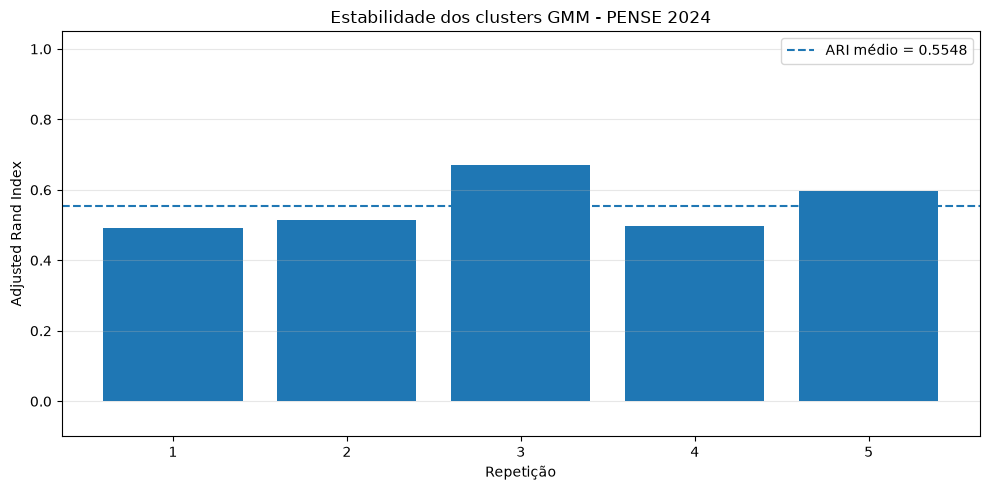


Análise de estabilidade concluída.


In [11]:

# ============================================================
# 10. ESTABILIDADE DOS CLUSTERS GMM
# ADJUSTED RAND INDEX (ARI)
# ============================================================

from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture

N_REPETICOES = 5
PERCENTUAL_AMOSTRA = 0.80
MAX_REFERENCIA = 10000

rng = np.random.default_rng(42)

# ------------------------------------------------------------
# 10.1. AMOSTRA DE REFERÊNCIA
# ------------------------------------------------------------

n_referencia = min(MAX_REFERENCIA, len(X_array))

idx_referencia = rng.choice(
    len(X_array),
    size=n_referencia,
    replace=False
)

X_referencia = X_array[idx_referencia]

# Classificação do modelo original
labels_original = modelo_gmm.predict(X_referencia)

# ------------------------------------------------------------
# 10.2. TREINAR MODELOS COM DIFERENTES AMOSTRAS
# ------------------------------------------------------------

resultados_estabilidade_gmm = []

for repeticao in range(N_REPETICOES):

    rng_rep = np.random.default_rng(100 + repeticao)

    n_treino = int(
        len(X_array) * PERCENTUAL_AMOSTRA
    )

    idx_treino = rng_rep.choice(
        len(X_array),
        size=n_treino,
        replace=False
    )

    modelo_teste = GaussianMixture(
        n_components=melhor_k_gmm,
        covariance_type=modelo_gmm.covariance_type,
        random_state=100 + repeticao,
        n_init=3,
        max_iter=300,
        reg_covar=1e-6
    )

    modelo_teste.fit(X_array[idx_treino])

    # Classificar a mesma amostra de referência
    labels_teste = modelo_teste.predict(X_referencia)

    # Comparar classificações
    ari = adjusted_rand_score(
        labels_original,
        labels_teste
    )

    resultados_estabilidade_gmm.append({
        "Repeticao": repeticao + 1,
        "ARI": ari,
        "Convergiu": modelo_teste.converged_,
        "Iteracoes": modelo_teste.n_iter_
    })

# ------------------------------------------------------------
# 10.3. RESULTADOS
# ------------------------------------------------------------

df_estabilidade_gmm = pd.DataFrame(
    resultados_estabilidade_gmm
)

print("=" * 70)
print("ESTABILIDADE DOS CLUSTERS GMM")
print("=" * 70)

display(df_estabilidade_gmm.round(4))

ari_medio_gmm = df_estabilidade_gmm["ARI"].mean()

ari_desvio_gmm = df_estabilidade_gmm["ARI"].std()

print(f"\nARI médio: {ari_medio_gmm:.4f}")
print(f"Desvio padrão: {ari_desvio_gmm:.4f}")

# ------------------------------------------------------------
# 10.4. GRÁFICO
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    df_estabilidade_gmm["Repeticao"],
    df_estabilidade_gmm["ARI"]
)

plt.axhline(
    ari_medio_gmm,
    linestyle="--",
    label=f"ARI médio = {ari_medio_gmm:.4f}"
)

plt.ylim(-0.1, 1.05)

plt.xlabel("Repetição")
plt.ylabel("Adjusted Rand Index")

plt.title("Estabilidade dos clusters GMM - PENSE 2024")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nAnálise de estabilidade concluída.")
